# Pedestrian crossing: RL car with and without V2X intention (version 6)

The question: does an RL car (PPO-LSTM) become safer when a roadside unit (RSU) sends it the pedestrian's track and predicted intention over V2X? The baseline is the same RL car with its own sensors only, as in the SmartNets 2025 paper.

| Role | What it does |
|---|---|
| Pedestrian | Gap acceptance with hesitation (version 5). Walks at 1.1–1.5 m/s. Attentive pedestrians slow to 0.74× their speed in the last 2 m before the curb, then stop and judge the gap. 15% are distracted: they keep their speed and walk straight across. Parked cars hide a pedestrian who is off the road until the car is 12 m away. |
| RSU | Sees the pedestrian at all times (0.3 m and 0.15 m/s noise). Keeps a 1 s track and runs the intention predictor (probability of walking into the road without stopping). Broadcasts position, speed, measurement time and that probability every 0.1 s. V2X delay 0–100 ms, 1% loss. |
| Car | PPO-LSTM agent, speed control only (go, keep speed, brake), one decision every 0.3 s. Fuses the V2X track with its own sensors. Acts on the received intention probability, or runs the same predictor on its own track when no fresh V2X message exists. A safety floor using the car's own sensors is re-checked every 0.1 s and aims to stop 1.4 m before the crossing. |

Changes from version 5:

| # | Version 5 | Version 6 |
|---|---|---|
| 1 | Walking speed 1.8–2.2 m/s | 1.1–1.5 m/s; attentive pedestrians slow to 0.74× within 2 m of the curb. Observed values: 1.277 m/s approaching and 0.943 m/s while appraising traffic (Gorrini et al., arXiv:1711.00728). That distracted pedestrians do not slow down is a modelling assumption. |
| 2 | Swerving allowed | Speed control only |
| 3 | Shield braked toward the crossing line and released after small overshoots; it caused collisions | Safety floor stops at a line 1.4 m before the crossing and brakes only when it can still stop, or when someone is on the road |
| 4 | V2X sent inferred I, g, H without position | V2X sends position, speed and a learned, calibrated intention probability. An intention field is a proposed extension of today's messages |
| 5 | Best checkpoint chosen on 100 validation scenarios, which rarely contain a collision | 1,000 validation scenarios |
| 6 | Collision penalty −100 | −500 (reward scale 0.02) |
| 7 | 300 test scenarios | 2,000 test scenarios, per-episode results saved, paired McNemar tests, Clopper–Pearson intervals |
| 8 | Validation and testing took the single most likely action | The policy is used as it was trained: actions are sampled, with a fixed random seed per scenario. With three actions, the most likely one was almost never "brake", so good policies looked like "always go" |
| 9 | PPO always started from random weights | The V2X car first imitates the calibrated V2X rule (intention above 0.05), then PPO fine-tunes it. The imitation version is kept unless PPO beats it on the validation scenarios. The no-V2X car (your SmartNets setting) still starts from scratch; a from-scratch V2X car is kept as an ablation |

Order: run every cell from the top. Cell B trains the predictor (a few minutes), then 5 runs without V2X (about 25 minutes each on a CPU), 5 runs with V2X (imitation about 5 minutes plus 15 minutes of fine-tuning each) and 2 from-scratch V2X runs (25 minutes each): about 4.5 hours in total. Finished runs are found and skipped, so you can stop and resume. Cell C evaluates everything on the same test scenarios and chooses one run per variant, and whether it acts greedily or by sampling, on the validation scenarios only. Cell D tests V2X loss, delay and RSU failure. Cell E draws the plots.


Code of the paper *Insight Before Sight* (IEEE T-ITS). Final run: threshold 0.05. Results of this run are in `reproduce/data/`; the trained networks are in `reproduce/models/`.

In [1]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


## Base code (versions 3–5)
Environment, recurrent PPO and evaluation helpers. Version 6 builds on these.

In [2]:
# ===== CELL A1: setup
# ============================================================
# Pedestrian crossing with V2X-communicated inferred intention and hesitation
# Recurrent PPO (LSTM). Corrected version.
#
# Every change from the previous notebook is marked "FIX n", with n matching the
# list of mistakes. Observation stays 14-D and there are still 4 actions:
#   obs = [xv, yv, sv, xp, yp, sp, xc, yc, ttc, I_v2x, gx_v2x, gy_v2x, H_v2x, q_v2x]  (now scaled, FIX 17)
#   actions: 0 = keep speed, 1 = brake, 2 = dodge right, 3 = dodge left, 4 = go (regain cruise speed; FIX 4)
# ============================================================
import os, math, json, hashlib, time
from dataclasses import dataclass, asdict, field
from collections import deque

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.distributions import Categorical
import gymnasium as gym
from gymnasium import spaces

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch device:", device)


@dataclass
class EnvConfig:
    # time and geometry
    dt: float = 0.1                  # FIX 2: 0.1 s steps (was 1 time unit per step, 1-2 decisions per episode)
    max_steps: int = 300             # 30 s
    action_repeat: int = 3           # one decision every 0.3 s; physics, V2X and collision checks every 0.1 s
    w: float = 2.0                   # lane width (conflict strip is xc +/- w/2)
    l: float = 4.0                   # car length
    car_w: float = 1.8               # car width, used by the collision test (FIX 9)
    ped_r: float = 0.4               # pedestrian radius, used by the collision test (FIX 9)
    near_miss: float = 3.0           # your 3 m radius, now a near-miss margin
    xc: float = 45.0                 # FIX 18: fixed values written as constants (randint(45, 46) always gave 45)
    yc: float = 70.0
    xv0: float = 45.0
    yv0: tuple = (36.0, 44.0)        # car start (centre); front is 24-32 m from the crosswalk
    # car
    v_cruise: tuple = (6.5, 8.5)     # m/s, drawn per episode
    a_go: float = 2.0                # FIX 4: new action 4 "go" regains cruise speed at 2 m/s^2
    a_brake: float = 2.8             # your 2.8, now m/s^2 (FIX 3: decisions start early enough to stop)
    a_dodge: float = 3.0
    v_dodge_min: float = 2.0
    lat_speed: float = 2.0           # m/s sideways while dodging
    road_half: float = 3.0           # road spans xc +/- 3
    # pedestrian
    xp0: tuple = (41.0, 74.0)
    sp: tuple = (1.8, 2.2)
    band: float = 3.0                # hesitation happens within xc +/- band
    pre_roll: float = 2.0            # FIX 20: seconds of pedestrian motion seen by V2X before the episode starts
    # pedestrian model (version 5). "coinflip" reproduces versions 3 and 4 exactly.
    ped_model: str = "coinflip"      # "coinflip": a fresh random move every second near the road
                                     # "gap": gap acceptance; the pedestrian crosses when the car leaves enough time
    crit_gap: tuple = (1.5, 5.0)     # gap: each pedestrian's critical gap (s), drawn once per episode
    judge_noise: float = 0.3         # gap: relative error when the pedestrian judges the car's arrival time
    gap_margin: float = 1.0          # gap: within +/- this of the critical gap the decision is unclear
    curb_offset: float = 0.3         # gap: the pedestrian waits 0.3 m outside the road edge
    recheck: float = 0.5             # gap: a waiting pedestrian looks again every 0.5 s
    hes_step: tuple = (0.5, 1.5)     # gap: a hesitating pedestrian steps out for 0.5-1.5 s (1-3 m) ...
    hes_stop: float = 0.6            # ... then stands for 0.6 s before deciding again
    yield_speed: float = 1.0         # gap: a car slower than this (m/s) is seen as giving way
    p_distracted: float = 0.15       # gap: share of pedestrians who do not look and walk straight across
    p_interact: float = 0.7          # gap: share of episodes in which the pedestrian reaches the curb near the car's arrival
    meet_window: tuple = (-1.0, 5.0) # gap: in those episodes, the pedestrian reaches the curb 1 s after to 5 s before the car would
    hes_period: float = 1.0          # FIX 1: a new move is drawn every 1 s (your original step length)
    # partial observability of pedestrian speed (unchanged)
    po_zone: float = 12.0
    sp_drop: float = 0.9
    sp_noise_far: float = 0.05
    sp_noise_near: float = 0.50
    # limited sensing (version 4). "full" reproduces version 3 exactly, including the checkpoint folder name.
    ego_sensing: str = "full"        # "full", or "occluded": parked cars hide a pedestrian who is off the road
    occlusion_gap: float = 12.0      # occluded: a hidden pedestrian becomes visible when the car front is this close (m)
    ego_pos_noise: float = 0.3       # occluded: std of the car's own pedestrian position estimate (m)
    # inference window (FIX 6: thresholds now in m/s)
    win: int = 10                    # 1 s of history
    stop_thr: float = 0.15
    flip_thr: float = 0.10
    # V2X channel
    v2x_delay: tuple = (0, 1)        # steps (0-100 ms)
    v2x_loss: float = 0.01
    v2x_age_cap: int = 10            # 1 s
    noise_I: float = 0.05
    noise_g: float = 0.08
    noise_H: float = 0.07
    noise_conf: float = 0.05
    # reward, computed from the true state only (FIX 5)
    r_collision: float = -100.0
    r_success: float = 20.0          # FIX 7: paid when the car has passed, checked after the move
    r_time: float = -0.1             # per step (1 per second of waiting)
    r_near: float = -1.0             # per step, scaled by (1 - d / near_miss) while the pedestrian is on the road
    r_brake: float = -0.01           # comfort
    r_dodge: float = -0.05
    r_slow: float = -0.05            # per 0.1 s, times (1 - v / v_cruise), only when the true state shows no conflict: waiting without a reason
    r_ghost_brake: float = 0.0       # optional, per 0.1 s: braking when the true state shows no conflict (off by default; -0.2 made the car too bold)
    r_timeout: float = -20.0

    def key(self):
        d = asdict(self)
        if d.get("ego_sensing", "full") == "full":     # full sensing keeps the version-3 key, so those checkpoints are reused
            for k in ("ego_sensing", "occlusion_gap", "ego_pos_noise"):
                d.pop(k, None)
        if d.get("ped_model", "coinflip") == "coinflip":   # the coin-flip pedestrian keeps the version-3/4 key
            for k in ("ped_model", "crit_gap", "judge_noise", "gap_margin", "curb_offset", "recheck", "hes_step", "hes_stop", "yield_speed",
                      "p_distracted", "p_interact", "meet_window"):
                d.pop(k, None)
        return hashlib.md5(json.dumps(d, sort_keys=True).encode()).hexdigest()[:8]


PyTorch device: cpu


In [3]:
# ===== CELL A2: environment
class PedestrianCrossingEnv(gym.Env):
    """Car drives north on x = xc toward a crosswalk at y = yc. A pedestrian crosses from right to left on y = yc.

    Changes from the previous version, by mistake number:
      1  hesitation probabilities: forward 1-h, stand h/2, back h/2
      2  physics every 0.1 s, a decision every 0.3 s from the start
      3  braking starts early enough to stop
      4  action 0 regains cruise speed, so a car that yielded can drive on
      5  reward uses the true state; V2X appears only in the observation
      6  confidence q no longer drops when the pedestrian stands still
      7  success reward checked after the move
      8  "future position" projection removed
      9  collision tested on the car footprint after each 0.1 s move
      15 message age grows by one per step
      16 ttc is time for the car front to reach the crosswalk, capped at 10 s
      17 observation scaled to about [-1, 1]
      18 constants written as constants
      20 the inference is warm when the episode starts
    """
    metadata = {"render_modes": []}

    def __init__(self, hesitation_prob=0.2, enable_v2x=True, cfg: EnvConfig = None):
        super().__init__()
        self.cfg = cfg or EnvConfig()
        self.h = float(hesitation_prob)
        self.enable_v2x = bool(enable_v2x)
        self.observation_space = spaces.Box(-np.inf, np.inf, shape=(14,), dtype=np.float32)
        self.action_space = spaces.Discrete(5)   # FIX 4: action 4 = go

    # ---------- pedestrian ----------
    def _ped_move(self):
        if self.cfg.ped_model == "gap":
            return self._ped_move_gap()
        c, rng = self.cfg, self.ped_rng       # scenario stream: the same for every policy, ON or OFF
        if abs(self.xp - c.xc) <= c.band:
            if self.hes_timer <= 0:
                # FIX 1: was p=[h/2, 1-h, h/2] for [-1, 0, +1], so h = 0 meant "stand still forever"
                self.ped_dir = int(rng.choice([-1, 0, 1], p=[1.0 - self.h, self.h / 2, self.h / 2]))
                self.hes_timer = int(round(c.hes_period / c.dt))
            self.hes_timer -= 1
        else:
            self.ped_dir, self.hes_timer = -1, 0
        self.xp += self.ped_dir * self.sp * c.dt

    # ---------- gap-acceptance pedestrian (version 5) ----------
    def _car_arrival(self):
        """Seconds until the car front reaches the crosswalk, as the pedestrian judges it from the car's
        current speed. 0 if the car is on the crosswalk, infinite once it has passed or when it is giving way."""
        c = self.cfg
        gap = self._front_gap()
        if self.yv - c.l / 2 > c.yc + c.ped_r:          # car has passed
            return float("inf")
        if gap <= 0:                                     # car is on the crosswalk
            return 0.0
        if self.sv < c.yield_speed:                      # car (almost) stopped before the crosswalk: giving way
            return float("inf")
        return gap / self.sv

    def _ped_decide(self, stepped_out=False):
        c = self.cfg
        t_arr, g = self._car_arrival(), self.crit_gap
        if np.isfinite(t_arr):                           # people misjudge how soon a car arrives
            t_arr = max(0.0, t_arr * (1.0 + self.ped_rng.normal(0, c.judge_noise)))
        if t_arr >= g + c.gap_margin:
            choice = "cross"
        elif t_arr <= g - c.gap_margin:
            choice = "wait"
        elif self.ped_rng.random() < self.h:             # unclear gap: hesitate with probability h
            choice = "hesitate"
        else:
            choice = "cross" if t_arr >= g else "wait"
        if choice == "cross":
            self.ped_state = "cross"
        elif choice == "wait":
            self.ped_state, self.ped_timer = ("back", 0.0) if stepped_out else ("wait", c.recheck)
        elif stepped_out:                                # already stepped out: stand again
            self.ped_state, self.ped_timer = "hes_stop", c.hes_stop
        else:
            self.ped_state, self.ped_timer = "hes_step", float(self.ped_rng.uniform(*c.hes_step))

    def _ped_move_gap(self):
        c, dt = self.cfg, self.cfg.dt
        curb = c.xc + c.road_half + c.curb_offset
        st = self.ped_state
        if st == "approach":
            self.xp -= self.sp * dt
            if self.xp <= curb:
                if self.distracted:                      # does not look: keeps walking
                    self.ped_state = "cross"
                else:
                    self.xp = curb
                    self._ped_decide()
        elif st == "wait":
            self.ped_timer -= dt
            if self.ped_timer <= 1e-9:
                self._ped_decide()
        elif st == "hes_step":
            self.xp -= self.sp * dt
            self.ped_timer -= dt
            if self.ped_timer <= 1e-9:
                self.ped_state, self.ped_timer = "hes_stop", c.hes_stop
        elif st == "hes_stop":
            self.ped_timer -= dt
            if self.ped_timer <= 1e-9:
                self._ped_decide(stepped_out=True)
        elif st == "back":
            self.xp += self.sp * dt
            if self.xp >= curb:
                self.xp, self.ped_state, self.ped_timer = curb, "wait", c.recheck
        else:                                            # cross
            self.xp -= self.sp * dt

    # ---------- inference from motion ----------
    def _reset_inference(self):
        n = self.cfg.win
        self.I_smooth = 0.0
        self.vx_hist, self.vy_hist, self.spd_hist = deque(maxlen=n), deque(maxlen=n), deque(maxlen=n)
        self.sign_hist, self.band_hist = deque(maxlen=n), deque(maxlen=n)
        self.prev_xp, self.prev_yp = self.xp, self.yp

    def _update_inference(self):
        c = self.cfg
        vx = (self.xp - self.prev_xp) / c.dt          # FIX 6: velocities in m/s, so thresholds keep their meaning at any dt
        vy = (self.yp - self.prev_yp) / c.dt
        self.prev_xp, self.prev_yp = self.xp, self.yp
        self.vx_hist.append(vx); self.vy_hist.append(vy); self.spd_hist.append(math.hypot(vx, vy))
        self.sign_hist.append(int(np.sign(vx)) if abs(vx) > c.flip_thr else 0)
        self.band_hist.append(int(abs(self.xp - c.xc) <= c.band))

    def _infer(self):
        c = self.cfg
        if len(self.spd_hist) < 2:
            return 0.0, 0.0, 0.0, 0.0, 0.0
        spd, vx, vy = np.asarray(self.spd_hist), np.asarray(self.vx_hist), np.asarray(self.vy_hist)
        mx, my = float(vx.mean()), float(vy.mean())
        mn = math.hypot(mx, my)
        gx, gy = (mx / mn, my / mn) if mn >= c.stop_thr else (0.0, 0.0)
        stop_ratio = float(np.mean(spd < c.stop_thr))
        s = [v for v in self.sign_hist if v != 0]
        flip_rate = sum(a != b for a, b in zip(s[:-1], s[1:])) / (len(s) - 1) if len(s) > 1 else 0.0
        band_ratio = float(np.mean(self.band_hist))
        H = float(np.clip((0.6 * stop_ratio + 0.4 * flip_rate) * (0.7 + 0.6 * band_ratio), 0, 1))
        toward = float(np.mean(vx < -c.flip_thr))
        speed_score = float(np.clip(spd.mean() / (c.stop_thr * 4), 0, 1))
        raw_I = float(np.clip((0.55 * toward + 0.45 * speed_score) * (1 - 0.8 * H), 0, 1))
        self.I_smooth = 0.85 * self.I_smooth + 0.15 * raw_I
        # FIX 6: confidence reflects how much history the estimate rests on, not how fast the pedestrian walks.
        # (Before, q fell for a pedestrian standing in the lane, which then looked safe.)
        conf = len(self.spd_hist) / c.win
        return float(self.I_smooth), gx, gy, H, conf

    # ---------- V2X ----------
    def _v2x_send(self, I, gx, gy, H, conf):
        c, rng = self.cfg, self.noise_rng     # noise stream: V2X loss, delay and noise
        if not self.enable_v2x or rng.random() < c.v2x_loss:
            return
        msg = (float(np.clip(I + rng.normal(0, c.noise_I), 0, 1)),
               float(np.clip(gx + rng.normal(0, c.noise_g), -1, 1)),
               float(np.clip(gy + rng.normal(0, c.noise_g), -1, 1)),
               float(np.clip(H + rng.normal(0, c.noise_H), 0, 1)),
               float(np.clip(conf + rng.normal(0, c.noise_conf), 0, 1)))
        delay = int(rng.integers(c.v2x_delay[0], c.v2x_delay[1] + 1))
        self.queue.append((self.t + delay, msg))

    def _v2x_deliver(self):
        # FIX 15: called once per step, so the age grows by exactly one per step without a new message
        arrived = False
        while self.queue and self.queue[0][0] <= self.t:
            _, self.msg = self.queue.popleft()
            self.age, arrived = 0, True
        if not arrived:
            self.age = min(self.age + 1, 255)

    def _v2x_q(self):
        if not self.enable_v2x:
            return 0.0
        return float(np.clip(self.msg[4] * math.exp(-3.0 * min(self.age / self.cfg.v2x_age_cap, 1.0)), 0, 1))

    # ---------- geometry ----------
    def _visible(self):
        """Can the car's own sensors see the pedestrian? Always, with full sensing. With occlusion, parked cars
        hide a pedestrian who is off the road until the car front is within occlusion_gap of the crosswalk."""
        c = self.cfg
        if c.ego_sensing == "full":
            return True
        return abs(self.xp - c.xc) <= c.road_half or self._front_gap() <= c.occlusion_gap

    def _conflict(self, perceived=False):
        """True state: the pedestrian is on the road, or will reach it before the car could pass.
        perceived=True (used by the shield): a pedestrian the car cannot see is not known."""
        c = self.cfg
        if perceived and not self._visible():
            return False
        gap = self._front_gap()
        if gap < -(c.l + c.ped_r):                      # car already past the crosswalk
            return False
        if abs(self.xp - c.xc) <= c.road_half:          # pedestrian on the road
            return True
        if self.xp < c.xc:                              # pedestrian has crossed
            return False
        t_pass = (max(gap, 0.0) + c.l + c.ped_r) / max(self.sv, 0.5 * self.v_cruise)
        t_ped = (self.xp - (c.xc + c.road_half)) / max(self.sp, 0.1)
        return t_ped <= t_pass + 1.0

    def _front_gap(self):
        return self.cfg.yc - (self.yv + self.cfg.l / 2)          # metres from car front to crosswalk line

    def _collision(self):
        # FIX 8, 9: footprint test after every 0.1 s move (car moves at most 0.85 m per step)
        c = self.cfg
        return (abs(self.xp - self.xv) <= c.car_w / 2 + c.ped_r) and (abs(self.yp - self.yv) <= c.l / 2 + c.ped_r)

    def _sp_observed(self):
        c, rng = self.cfg, self.noise_rng
        if self._front_gap() <= c.po_zone:
            if rng.random() < c.sp_drop:
                return 0.0
            return max(0.0, self.sp * (1 + rng.normal(0, c.sp_noise_near)))
        return max(0.0, self.sp * (1 + rng.normal(0, c.sp_noise_far)))

    def _obs(self):
        c = self.cfg
        ttc = min(max(self._front_gap(), 0.0) / max(self.sv, 0.5), 10.0)    # FIX 16
        I, gx, gy, H, _ = self.msg if self.enable_v2x else (0.0, 0.0, 0.0, 0.0, 0.0)
        if c.ego_sensing == "full":
            o = np.array([                                                      # FIX 17: scaled inputs
                (self.xv - c.xc) / c.road_half, (self.yv - c.yc) / 30.0, self.sv / 8.5,
                (self.xp - c.xc) / 30.0, (self.yp - c.yc) / 5.0, self._sp_observed() / 2.2,
                c.xc / 100.0, c.yc / 100.0, ttc / 10.0,
                I, gx, gy, H, self._v2x_q()], dtype=np.float32)
            return o
        # occluded: slots 6 and 7 (constants above) carry "pedestrian visible" and "time since last seen"
        if self._visible():
            xp_m = self.xp + self.noise_rng.normal(0, c.ego_pos_noise)
            ped = ((xp_m - c.xc) / 30.0, (self.yp - c.yc) / 5.0, self._sp_observed() / 2.2)
            vis = 1.0
        else:
            ped, vis = (0.0, 0.0, 0.0), 0.0
        o = np.array([
            (self.xv - c.xc) / c.road_half, (self.yv - c.yc) / 30.0, self.sv / 8.5,
            *ped, vis, min(self.since_seen, 5.0) / 5.0, ttc / 10.0,
            I, gx, gy, H, self._v2x_q()], dtype=np.float32)
        return o

    # ---------- gym API ----------
    def reset(self, *, seed=None, options=None):
        super().reset(seed=seed)          # per-episode seeds give every policy the same scenarios in evaluation (FIX 13)
        c, rng = self.cfg, self.np_random
        self.t = 0
        self.xv, self.yv = c.xv0, float(rng.uniform(*c.yv0))
        self.v_cruise = float(rng.uniform(*c.v_cruise)); self.sv = self.v_cruise
        self.sp = float(rng.uniform(*c.sp))
        # FIX 20: the roadside unit has watched the pedestrian before the car arrives. Walk the pedestrian
        # for pre_roll seconds first, so the inference and the V2X message start warm (before, I started at 0
        # in every episode and needed about 2 s to rise, so a pedestrian close to the road looked uncommitted).
        n_pre = int(round(c.pre_roll / c.dt))
        self.xp, self.yp = float(rng.uniform(*c.xp0)) + self.sp * c.pre_roll, c.yc
        # v4: two random streams. The pedestrian uses ped_rng, so with the same seed it walks and hesitates the
        # same way whatever the car does and whether V2X is on or off. V2X and sensor noise use noise_rng.
        self.ped_rng = rng
        self.noise_rng = np.random.default_rng(int(rng.integers(2**62)))
        self.ped_dir, self.hes_timer = -1, 0
        if c.ped_model == "gap":
            curb = c.xc + c.road_half + c.curb_offset
            self.crit_gap = float(rng.uniform(*c.crit_gap))
            self.distracted = bool(rng.random() < c.p_distracted)
            if rng.random() < c.p_interact:              # meet the car: reach the curb shortly before or after it would
                t_car = max(self._front_gap(), 0.0) / self.v_cruise
                tau = float(rng.uniform(*c.meet_window))
                self.xp = curb + self.sp * max(t_car - tau, 0.0) + self.sp * c.pre_roll
            self.ped_timer = 0.0
            self.ped_state = "approach" if self.xp > curb else "cross"
        self._reset_inference()
        self.queue, self.msg, self.age = deque(), (0.0, 0.0, 0.0, 0.0, 0.0), 255
        self.t = -n_pre
        for _ in range(n_pre):
            self._ped_move()
            self._update_inference()
            self._v2x_send(*self._infer())
            self.t += 1
            self._v2x_deliver()
        self.min_dist = math.hypot(self.xp - self.xv, self.yp - self.yv)
        self.since_seen = 0.0 if self._visible() else 5.0     # occluded mode: seconds since the car last saw the pedestrian
        self.near_miss_hit = False
        return self._obs(), {}

    def _substep(self, a):
        c = self.cfg
        # 1) car (FIX 2: the action applies from the start, held for action_repeat steps)
        if a == 0:   # keep the current speed
            pass
        elif a == 4:   # go: regain cruise speed (FIX 4)
            self.sv = min(self.sv + c.a_go * c.dt, self.v_cruise)
        elif a == 1:
            self.sv = max(self.sv - c.a_brake * c.dt, 0.0)
        else:
            self.sv = max(self.sv - c.a_dodge * c.dt, min(self.sv, c.v_dodge_min))
            self.xv += (1 if a == 2 else -1) * c.lat_speed * c.dt
            self.xv = float(np.clip(self.xv, c.xc - c.road_half + c.car_w / 2, c.xc + c.road_half - c.car_w / 2))
        self.yv += self.sv * c.dt
        # 2) pedestrian
        self._ped_move()
        self.since_seen = 0.0 if self._visible() else self.since_seen + c.dt
        # 3) outcome on the positions after the move (FIX 7, 8, 9)
        collision = self._collision()
        passed = (self.yv - c.l / 2) > c.yc + c.ped_r
        d = math.hypot(self.xp - self.xv, self.yp - self.yv)
        self.min_dist = min(self.min_dist, d)
        on_road = abs(self.xp - c.xc) <= c.road_half
        # 4) reward from the true state only (FIX 5)
        r = c.r_time
        if on_road and d < c.near_miss:
            r += c.r_near * (1 - d / c.near_miss)
            self.near_miss_hit = True
        if a == 1:
            r += c.r_brake
            if not self._conflict():
                r += c.r_ghost_brake
        if a in (2, 3): r += c.r_dodge
        if not collision and not passed and not self._conflict():
            r += c.r_slow * (1.0 - self.sv / self.v_cruise)
        if collision: r += c.r_collision
        elif passed: r += c.r_success
        # 5) inference, V2X send, then one delivery per step (FIX 15)
        self._update_inference()
        self._v2x_send(*self._infer())
        self.t += 1
        self._v2x_deliver()
        terminated = bool(collision or passed)
        truncated = bool(self.t >= c.max_steps and not terminated)
        if truncated:
            r += c.r_timeout
        info = {"collision": collision, "passed": passed, "time_limit": truncated,
                "near_miss": self.near_miss_hit, "min_dist": self.min_dist, "t": self.t * c.dt}
        return float(r), terminated, truncated, info

    def step(self, action):
        """One decision lasts cfg.action_repeat steps of dt (0.3 s by default).
        The car, pedestrian, V2X and collision test still update every 0.1 s."""
        total = 0.0
        for _ in range(self.cfg.action_repeat):
            r, terminated, truncated, info = self._substep(int(action))
            total += r
            if terminated or truncated:
                break
        return self._obs(), total, terminated, truncated, info


In [4]:
# ===== CELL A3: model
class LSTMActorCritic(nn.Module):
    """fc1 -> ReLU -> LSTM -> actor (4 logits) / critic (1 value). Runs over sequences so the recurrent
    weights are trained (FIX 10). `starts` marks steps where a new episode begins; the state is zeroed there."""
    def __init__(self, input_dim=14, hidden_dim=128, num_actions=5):
        super().__init__()
        self.hidden_dim = hidden_dim
        self.fc1 = nn.Linear(input_dim, hidden_dim)
        self.lstm = nn.LSTM(hidden_dim, hidden_dim, batch_first=True)
        self.actor_fc = nn.Linear(hidden_dim, num_actions)
        self.critic_fc = nn.Linear(hidden_dim, 1)

    def init_hidden(self, batch_size=1):
        z = torch.zeros(1, batch_size, self.hidden_dim, device=next(self.parameters()).device)
        return (z, z.clone())

    def forward(self, x, hidden, starts=None):
        # x: (B, T, D); hidden: ((1,B,H), (1,B,H)); starts: (B, T) in {0, 1}
        B, T, _ = x.shape
        z = torch.relu(self.fc1(x))
        h, c = hidden
        outs = []
        for t in range(T):
            if starts is not None:
                keep = (1.0 - starts[:, t]).view(1, B, 1)
                h, c = h * keep, c * keep
            o, (h, c) = self.lstm(z[:, t:t + 1], (h, c))
            outs.append(o)
        out = torch.cat(outs, dim=1)
        return self.actor_fc(out), self.critic_fc(out).squeeze(-1), (h, c)


In [5]:
# ===== CELL A4: recurrent PPO
@dataclass
class PPOConfig:
    total_frames: int = 800_000      # decisions of 0.3 s (2.4 M physics steps of 0.1 s)
    num_envs: int = 8                # 8 episodes run side by side, one batched forward pass per step
    rollout: int = 256               # steps per env per update (2,048 frames per update)
    seq_len: int = 16
    batch_seqs: int = 32
    epochs: int = 4
    gamma: float = 0.97              # per 0.3 s decision, about 0.99 per 0.1 s
    lam: float = 0.95
    clip: float = 0.2
    lr: float = 3e-4                 # FIX 13: one learning rate for ON and OFF
    weight_decay: float = 0.0        # FIX 10: weight decay erased the untrained recurrent weights
    vf_coef: float = 0.5
    ent_start: float = 0.05
    ent_end: float = 0.005
    max_grad: float = 0.5
    hidden: int = 128                # 1024 was 8.4 M parameters for 14 inputs
    reward_scale: float = 0.1        # v3: rewards x 0.1 for the value loss (the -100 collision shook the shared layers)
    lr_decay: bool = True            # v3: learning rate falls linearly to 5% of lr
    val_every: int = 20              # v3: check the policy every 20 updates on held-out scenarios
    val_episodes: int = 100
    val_seed0: int = 50_000          # validation seeds; the test seeds in evaluate() start at 10,000

    def key(self):
        d = asdict(self)
        if d.get("ego_sensing", "full") == "full":     # full sensing keeps the version-3 key, so those checkpoints are reused
            for k in ("ego_sensing", "occlusion_gap", "ego_pos_noise"):
                d.pop(k, None)
        return hashlib.md5(json.dumps(d, sort_keys=True).encode()).hexdigest()[:8]


def train_ppo(make_env, model, pc: PPOConfig, seed=0, log_every=10, verbose=True, val_policy=None):
    """Recurrent PPO over pc.num_envs copies of the environment. Fixes:
       FIX 10  updates run over 16-step sequences from the stored LSTM state, so W_hh gets gradients
       FIX 11  actions are sampled at temperature 1, the same distribution the update uses
       FIX 12  every step is used, with GAE and done masks; sequences reset the state at episode starts"""
    torch.manual_seed(seed); np.random.seed(seed)
    N, T, L = pc.num_envs, pc.rollout, pc.seq_len
    envs = [make_env() for _ in range(N)]
    D = envs[0].observation_space.shape[0]
    Hd = model.hidden_dim
    opt = torch.optim.Adam(model.parameters(), lr=pc.lr, weight_decay=pc.weight_decay)
    n_updates = pc.total_frames // (N * T)
    obs = np.stack([e.reset(seed=seed * 1000 + i)[0] for i, e in enumerate(envs)])
    hid = model.init_hidden(N)
    start = torch.ones(N)
    ep_ret = np.zeros(N)
    episodes = []
    log = dict(update=[], frames=[], ep_return=[], collision=[], success=[], timeout=[], near_miss=[], ep_time=[],
               val_update=[], val_return=[])
    best_val, best_state, best_u = -float("inf"), None, -1

    def validate():
        # v3: greedy policy on fixed held-out scenarios; score = mean episode return (the training objective)
        # v6: val_policy lets validation use the policy the way it is trained (sampled actions, seeded per scenario)
        env_v = make_env(); pol = (val_policy or NetPolicy)(model); total = 0.0
        for ep in range(pc.val_episodes):
            o, _ = env_v.reset(seed=pc.val_seed0 + ep); done = False
            pol.reset(pc.val_seed0 + ep) if val_policy else pol.reset()
            while not done:
                o, r, te, tr, _ = env_v.step(pol(env_v, o)); total += r; done = te or tr
        return total / pc.val_episodes
    t0 = time.time()
    for u in range(n_updates):
        if pc.lr_decay:
            for g in opt.param_groups:
                g["lr"] = pc.lr * max(1.0 - u / n_updates, 0.05)
        b_obs = torch.zeros(T, N, D); b_act = torch.zeros(T, N, dtype=torch.long); b_logp = torch.zeros(T, N)
        b_val = torch.zeros(T + 1, N); b_rew = torch.zeros(T, N); b_done = torch.zeros(T, N); b_start = torch.zeros(T, N)
        b_h = torch.zeros(T, N, Hd); b_c = torch.zeros(T, N, Hd)
        model.eval()
        with torch.no_grad():
            for t in range(T):
                x = torch.as_tensor(obs, dtype=torch.float32)
                b_obs[t] = x; b_start[t] = start; b_h[t] = hid[0][0].cpu(); b_c[t] = hid[1][0].cpu()
                logits, v, hid = model(x.view(N, 1, D).to(device), hid, start.view(N, 1).to(device))
                dist = Categorical(logits=logits[:, 0])
                a = dist.sample()
                b_act[t] = a.cpu(); b_logp[t] = dist.log_prob(a).cpu(); b_val[t] = v[:, 0].cpu()
                for i, e in enumerate(envs):
                    o, r, term, trunc, info = e.step(int(a[i]))
                    ep_ret[i] += r; b_rew[t, i] = r * pc.reward_scale
                    done = term or trunc
                    b_done[t, i] = float(done)
                    if done:
                        episodes.append(dict(ret=ep_ret[i], **{k: info[k] for k in ("collision", "passed", "time_limit", "near_miss", "t")}))
                        ep_ret[i] = 0.0
                        o, _ = e.reset()
                    start[i] = float(done)
                    obs[i] = o
            _, v_last, _ = model(torch.as_tensor(obs, dtype=torch.float32).view(N, 1, D).to(device), hid, start.view(N, 1).to(device))
            b_val[T] = v_last[:, 0].cpu()
        # GAE with done masks (FIX 12)
        adv = torch.zeros(T, N); last = torch.zeros(N)
        for t in reversed(range(T)):
            nonterm = 1.0 - b_done[t]
            delta = b_rew[t] + pc.gamma * b_val[t + 1] * nonterm - b_val[t]
            last = delta + pc.gamma * pc.lam * nonterm * last
            adv[t] = last
        ret = adv + b_val[:T]
        # cut each env's rollout into sequences of L steps (FIX 10)
        S = T // L
        def seqs(x):   # (T, N, ...) -> (N*S, L, ...)
            x = x[:S * L].transpose(0, 1)
            return x.reshape(N * S, L, *x.shape[2:])
        s_obs, s_act, s_logp, s_ret, s_adv, s_start = map(seqs, (b_obs, b_act, b_logp, ret, adv, b_start))
        s_h0 = b_h[:S * L:L].transpose(0, 1).reshape(N * S, Hd)
        s_c0 = b_c[:S * L:L].transpose(0, 1).reshape(N * S, Hd)
        ent_coef = pc.ent_start + (pc.ent_end - pc.ent_start) * u / max(n_updates - 1, 1)
        model.train()
        for _ in range(pc.epochs):
            perm = torch.randperm(N * S)
            for i in range(0, N * S, pc.batch_seqs):
                idx = perm[i:i + pc.batch_seqs]
                h0 = (s_h0[idx].unsqueeze(0).to(device), s_c0[idx].unsqueeze(0).to(device))
                logits, v, _ = model(s_obs[idx].to(device), h0, s_start[idx].to(device))
                dist = Categorical(logits=logits)
                logp = dist.log_prob(s_act[idx].to(device))
                a_mb = s_adv[idx].to(device); a_mb = (a_mb - a_mb.mean()) / (a_mb.std() + 1e-8)
                ratio = torch.exp(logp - s_logp[idx].to(device))      # FIX 11: same temperature on both sides
                pg = -torch.min(ratio * a_mb, torch.clamp(ratio, 1 - pc.clip, 1 + pc.clip) * a_mb).mean()
                vf = (s_ret[idx].to(device) - v).pow(2).mean()
                loss = pg + pc.vf_coef * vf - ent_coef * dist.entropy().mean()
                opt.zero_grad(); loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), pc.max_grad)
                opt.step()
        recent = episodes[-200:]
        if recent:
            log["update"].append(u); log["frames"].append((u + 1) * N * T)
            log["ep_return"].append(float(np.mean([e["ret"] for e in recent])))
            for k, kk in (("collision", "collision"), ("success", "passed"), ("timeout", "time_limit"), ("near_miss", "near_miss")):
                log[k].append(float(np.mean([e[kk] for e in recent])))
            log["ep_time"].append(float(np.mean([e["t"] for e in recent])))
        if verbose and (u % log_every == 0 or u == n_updates - 1) and recent:
            print(f"  update {u+1}/{n_updates}  frames {(u+1)*N*T:>7}  return {log['ep_return'][-1]:7.2f}  "
                  f"coll {log['collision'][-1]*100:5.1f}%  pass {log['success'][-1]*100:5.1f}%  "
                  f"near {log['near_miss'][-1]*100:5.1f}%  time {log['ep_time'][-1]:4.1f}s  ({time.time()-t0:.0f}s)")
        if (u + 1) % pc.val_every == 0 or u == n_updates - 1:
            vr = validate()
            log["val_update"].append(u); log["val_return"].append(vr)
            if vr > best_val:
                best_val, best_u = vr, u
                best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
    # v3: keep the best checkpoint on the validation scenarios, not the last one
    if best_state is not None:
        model.load_state_dict(best_state)
        log["best_update"] = best_u; log["best_val_return"] = best_val
        if verbose:
            print(f"  kept the policy from update {best_u+1} (validation return {best_val:.2f})")
    return log


In [6]:
# ===== CELL A5: policies, shield and evaluation
def shielded_action(env, a):
    """FIX 19: predicts where the pedestrian really is going.
    Replaces any action with 'brake' when the pedestrian is on the road, or will reach it before
    the car has passed, and the car is within its stopping distance plus 2 m."""
    if a == 1:
        return a
    c = env.cfg
    gap = env._front_gap()
    if gap < -c.l:                       # car already over the crosswalk
        return a
    if c.ped_model == "gap" and gap < 0:  # gap model: once on the crosswalk, clear it (a waiting pedestrian waits for that)
        return a
    stop_dist = env.sv ** 2 / (2 * c.a_brake) + env.sv * c.dt * c.action_repeat   # a decision is held for 0.3 s
    if env._conflict(perceived=True) and gap <= stop_dist + 2.0:   # the shield knows only what the car sees
        return 1
    return a


class NetPolicy:
    def __init__(self, model, greedy=True):
        self.m, self.greedy = model.eval(), greedy
    def reset(self):
        self.hid = self.m.init_hidden(1)
    @torch.no_grad()
    def __call__(self, env, obs):
        x = torch.as_tensor(obs, dtype=torch.float32, device=device).view(1, 1, -1)
        logits, _, self.hid = self.m(x, self.hid)
        return int(logits[0, 0].argmax()) if self.greedy else int(Categorical(logits=logits[0, 0]).sample())


class ConstPolicy:
    def __init__(self, a): self.a = a
    def reset(self): pass
    def __call__(self, env, obs): return self.a


def evaluate(env, policy, episodes=300, use_shield=False, seed0=10_000):
    """Same seeds for every policy (common random numbers), so ON, OFF and baselines face the same scenarios."""
    rows = []
    for ep in range(episodes):
        obs, _ = env.reset(seed=seed0 + ep)
        policy.reset(); done = False; acts = np.zeros(env.action_space.n)
        while not done:
            a = policy(env, obs)
            if use_shield:
                a = shielded_action(env, a)
            acts[a] += 1
            obs, r, term, trunc, info = env.step(a)
            done = term or trunc
        rows.append(dict(collision=info["collision"], passed=info["passed"], timeout=info["time_limit"],
                         near_miss=info["near_miss"], min_dist=info["min_dist"], time=info["t"],
                         brake_share=acts[1] / acts.sum()))
    df = pd.DataFrame(rows)
    ok = df[df.passed]
    return dict(collision_pct=100 * df.collision.mean(), near_miss_pct=100 * df.near_miss.mean(),
                success_pct=100 * df.passed.mean(), timeout_pct=100 * df.timeout.mean(),
                time_to_pass_s=float(ok.time.mean()) if len(ok) else float("nan"),
                brake_share_pct=100 * df.brake_share.mean(), episodes=episodes)


def save_ckpt(path, model, log, **extra):
    if os.path.dirname(path):
        os.makedirs(os.path.dirname(path), exist_ok=True)
    torch.save({"model_state": model.state_dict(), "hidden": model.hidden_dim, "num_actions": model.actor_fc.out_features,
                "log": log, "extra": extra}, path)


def load_ckpt(path):
    ck = torch.load(path, map_location=device, weights_only=False)
    m = LSTMActorCritic(14, ck["hidden"], ck.get("num_actions", 5)).to(device)
    m.load_state_dict(ck["model_state"]); m.eval()
    return m, ck


## Version 6
RSU sensing and intention prediction over V2X, the car's sensor fusion, the safety floor and the reference rules.

In [7]:
# ===== CELL V1: version 6 environment (car = PPO agent; RSU = sensor + intention predictor, sent over V2X)
# ============================================================
# Roles
#   Pedestrian: gap acceptance (version 5) with realistic walking speed 1.1-1.5 m/s. Attentive pedestrians slow to
#               0.74x their speed in the last 2 m before the curb (appraising phase; Gorrini et al., Milan:
#               1.277 m/s approaching, 0.943 m/s appraising). Distracted pedestrians (15%) keep their speed and
#               do not stop. Parked cars hide a pedestrian who is off the road until the car is 12 m away.
#   RSU:        sees the pedestrian at all times (0.3 m, 0.15 m/s noise), keeps a 1 s track, runs the intention
#               predictor and broadcasts (measurement time, position, speed, intention probability) every 0.1 s.
#               V2X: 0-100 ms delay, 1% loss by default.
#   Car:        PPO-LSTM agent. Fuses the V2X track with its own sensors, reads the received intention
#               probability (or runs the same predictor on its own track when no V2X message is fresh), and
#               chooses go / keep speed / brake every 0.3 s. Speed control only (no swerving).
#               Safety floor (car's own sensors) re-checked every 0.1 s: stop line 1.4 m before the crossing.
# ============================================================
from dataclasses import replace


@dataclass
class V6Config:
    appraise_zone: float = 2.0      # m before the curb where attentive pedestrians slow down
    appraise_factor: float = 0.74   # 0.943 / 1.277 (Gorrini et al., single pedestrians)
    sens_pos: float = 0.3           # m, position noise of RSU and car sensors
    sens_vel: float = 0.15          # m/s, speed noise
    v2x_loss: float = 0.01          # share of V2X messages lost
    extra_delay: int = 0            # extra V2X delay in 0.1 s steps (base delay 0-100 ms)
    max_age: int = 10               # a V2X track older than 1 s is dropped
    win: int = 10                   # predictor input: the last 1 s of track

    def key(self):
        return hashlib.md5(json.dumps(asdict(self), sort_keys=True).encode()).hexdigest()[:8]


ENV6 = EnvConfig(ego_sensing="occluded", ped_model="gap", r_collision=-500.0, sp=(1.1, 1.5))
STOP_MARGIN = ENV6.ped_r + 1.0      # the car aims to stop 1.4 m before the crosswalk centre line


def safety_floor(env, a):
    """Car's own sensors only. Before the stop line: brake if a seen pedestrian will be in the way and the car can
    still stop at the line, or if someone is already on the road. Past the line: brake only for a pedestrian on the
    road ahead; otherwise clear the crossing."""
    c = env.cfg
    gap = env._front_gap()
    if gap < -c.l:
        return a
    stop = env.sv ** 2 / (2 * c.a_brake) + env.sv * c.dt * c.action_repeat
    on_road = env._visible() and abs(env.xp - c.xc) <= c.road_half
    if gap < STOP_MARGIN:
        return 1 if on_road and env.xp > env.xv - c.car_w / 2 - c.ped_r - 0.5 else a
    if env._conflict(perceived=True) and (gap - STOP_MARGIN) <= stop + 2.0:
        if (gap - STOP_MARGIN) >= stop or on_road:
            return 1
    return a


def track_features(track, win):
    t = list(track)
    if not t:
        return np.zeros(2 * win, dtype=np.float32)
    while len(t) < win:
        t.insert(0, t[0])
    a = np.asarray(t, dtype=np.float32)
    return np.concatenate([a[:, 0] / 10.0, a[:, 1] / 1.5])


class IntentNet(nn.Module):
    def __init__(self, win=10, hidden=64):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(2 * win, hidden), nn.ReLU(), nn.Linear(hidden, hidden), nn.ReLU(), nn.Linear(hidden, 1))

    def forward(self, x):
        return self.net(x).squeeze(-1)


class IntentPredictor:
    """Track (distance to curb, speed; last 1 s) -> probability that the pedestrian walks into the road without
    stopping. Runs in numpy, so it costs almost nothing per step."""
    def __init__(self, state, temp=1.0, win=10):
        self.W = [state[k].detach().cpu().numpy() for k in
                  ("net.0.weight", "net.0.bias", "net.2.weight", "net.2.bias", "net.4.weight", "net.4.bias")]
        self.temp, self.win = float(temp), win

    def __call__(self, track):
        W = self.W
        x = track_features(track, self.win)
        h = np.maximum(W[0] @ x + W[1], 0.0)
        h = np.maximum(W[2] @ h + W[3], 0.0)
        z = float((W[4] @ h + W[5]).item()) / self.temp
        return 1.0 / (1.0 + math.exp(-z))


class V6Env(PedestrianCrossingEnv):
    ACTIONS = {0: 4, 1: 0, 2: 1}     # PPO actions -> car actions: 0 go (regain cruise), 1 keep speed, 2 brake

    def __init__(self, hesitation_prob=0.2, v2x=True, predictor=None, vcfg: V6Config = None, cfg: EnvConfig = None):
        super().__init__(hesitation_prob, enable_v2x=v2x, cfg=cfg or ENV6)
        self.v = vcfg or V6Config()
        self.predictor = predictor
        self.prior = self.cfg.p_distracted
        self.observation_space = spaces.Box(-np.inf, np.inf, shape=(11,), dtype=np.float32)
        self.action_space = spaces.Discrete(3)

    def _curb(self):
        c = self.cfg
        return c.xc + c.road_half + c.curb_offset

    # pedestrian: attentive pedestrians slow down in the appraising zone
    def _ped_move_gap(self):
        if self.ped_state == "approach" and not self.distracted and self.xp - self._curb() <= self.v.appraise_zone:
            sp0 = self.sp
            self.sp = sp0 * self.v.appraise_factor
            super()._ped_move_gap()
            self.sp = sp0
            return
        super()._ped_move_gap()

    def _reset_inference(self):
        super()._reset_inference()
        self.rsu_track, self.car_track = deque(maxlen=self.v.win), deque(maxlen=self.v.win)
        self.p_rsu = self.p_car = self.prior
        self.rsu_q, self.rsu_last, self.est = deque(), None, None

    def _measure(self):
        vx = self.vx_hist[-1] if len(self.vx_hist) else 0.0
        r = self.noise_rng
        return self.xp + r.normal(0, self.v.sens_pos), vx + r.normal(0, self.v.sens_vel)

    # RSU: measure, predict intention
    def _update_inference(self):
        super()._update_inference()
        x, vx = self._measure()
        self.rsu_track.append((x - self._curb(), vx))
        if self.predictor is not None:
            self.p_rsu = self.predictor(self.rsu_track)

    # RSU -> car over V2X
    def _v2x_send(self, *args):
        if not self.enable_v2x or self.noise_rng.random() < self.v.v2x_loss:
            return
        d, vx = self.rsu_track[-1]
        delay = int(self.noise_rng.integers(0, 2)) + self.v.extra_delay
        self.rsu_q.append((self.t + delay, (self.t, d + self._curb(), vx, self.p_rsu)))

    # car: receive, fuse with its own sensors, run its own predictor on what it sees
    def _v2x_deliver(self):
        while self.rsu_q and self.rsu_q[0][0] <= self.t:
            _, self.rsu_last = self.rsu_q.popleft()
        own = self._measure() if self._visible() else None
        rsu = None
        if self.rsu_fresh:
            age = self.t - self.rsu_last[0]
            rsu = (self.rsu_last[1] + self.rsu_last[2] * age * self.cfg.dt, self.rsu_last[2])
        if own and rsu:
            self.est = ((own[0] + rsu[0]) / 2, (own[1] + rsu[1]) / 2)
        else:
            self.est = own or rsu
        if own:
            self.car_track.append((own[0] - self._curb(), own[1]))
            if self.predictor is not None:
                self.p_car = self.predictor(self.car_track)

    @property
    def rsu_fresh(self):
        return self.rsu_last is not None and self.t - self.rsu_last[0] <= self.v.max_age

    @property
    def p_used(self):
        """Intention probability the car acts on: the received V2X value when fresh, else its own."""
        return self.rsu_last[3] if self.rsu_fresh else self.p_car

    def _obs(self):
        c = self.cfg
        gap = self._front_gap()
        ttc = min(max(gap, 0.0) / max(self.sv, 0.5), 10.0)
        if self.est is None:
            ped = [0.0, 0.0, 0.0, 0.0]
        else:
            x, vx = self.est
            ped = [1.0, (x - c.xc) / 30.0, vx / 1.5, float(abs(x - c.xc) <= c.road_half)]
        age = (self.t - self.rsu_last[0]) if self.rsu_fresh else self.v.max_age
        return np.array([self.sv / 8.5, gap / 30.0, ttc / 10.0, *ped, self.p_used, float(self.rsu_fresh),
                         float(self._visible()), age / self.v.max_age], dtype=np.float32)

    def step(self, action):
        total = 0.0
        for _ in range(self.cfg.action_repeat):
            a = safety_floor(self, self.ACTIONS[int(action)])      # the floor is re-checked every 0.1 s
            r, terminated, truncated, info = self._substep(a)
            total += r
            if terminated or truncated:
                break
        return self._obs(), total, terminated, truncated, info


In [8]:
# ===== CELL V2: intention predictor (supervised; trained once, used by the RSU and by the car)
def predictor_data(n_eps, seed0, hs=(0.2, 0.4), losses=(0.01, 0.3, 1.0), vcfg=None):
    """Track windows while a pedestrian approaches within 10 m of the curb. Label: distracted (will not stop).
    Windows come from the RSU track and from the car's own track. The approach does not depend on the car."""
    X, y, dist, ep_id = [], [], [], []
    k = 0
    for h in hs:
        for loss in losses:
            env = V6Env(h, v2x=True, predictor=None, vcfg=replace(vcfg or V6Config(), v2x_loss=loss))
            for ep in range(n_eps):
                s = seed0 + k; k += 1
                env.reset(seed=s); done = False
                while not done:
                    d = env.xp - env._curb()
                    if env.ped_state == "approach" and 0 < d <= 10.0:
                        for tr in (env.rsu_track, env.car_track):
                            if len(tr):
                                X.append(track_features(tr, env.v.win)); y.append(float(env.distracted)); dist.append(d); ep_id.append(s)
                    _, _, te, tr_, _ = env.step(0); done = te or tr_
    return np.array(X), np.array(y, dtype=np.float32), np.array(dist), np.array(ep_id)


def train_predictor(X, y, dist, ep_id, win=10, epochs=15, seed=0, verbose=True):
    from sklearn.metrics import roc_auc_score
    torch.manual_seed(seed)
    u = np.unique(ep_id); np.random.default_rng(seed).shuffle(u)
    tr_e, ca_e = set(u[:int(.7 * len(u))]), set(u[int(.7 * len(u)):int(.85 * len(u))])
    m_tr = np.array([e in tr_e for e in ep_id]); m_ca = np.array([e in ca_e for e in ep_id]); m_te = ~(m_tr | m_ca)
    net = IntentNet(win); opt = torch.optim.Adam(net.parameters(), 1e-3)
    Xt, yt = torch.tensor(X[m_tr]), torch.tensor(y[m_tr])
    for _ in range(epochs):
        perm = torch.randperm(len(yt))
        for i in range(0, len(yt), 512):
            b = perm[i:i + 512]
            loss = nn.functional.binary_cross_entropy_with_logits(net(Xt[b]), yt[b])
            opt.zero_grad(); loss.backward(); opt.step()
    with torch.no_grad():   # temperature scaling on the calibration split
        zc, yc = net(torch.tensor(X[m_ca])), torch.tensor(y[m_ca])
        temp = float(min(np.linspace(0.5, 3, 26), key=lambda T: float(nn.functional.binary_cross_entropy_with_logits(zc / T, yc))))
        p = torch.sigmoid(net(torch.tensor(X[m_te])) / temp).numpy()
    yt_, dt_ = y[m_te], dist[m_te]
    rep = {"samples": int(len(y)), "positive_share": float(y.mean()), "temperature": temp, "auc_all": float(roc_auc_score(yt_, p))}
    for lo, hi in ((3, 10), (2, 3), (1, 2), (0, 1)):
        s = (dt_ > lo) & (dt_ <= hi)
        if s.sum() and len(np.unique(yt_[s])) > 1:
            rep[f"auc_{lo}_{hi}m"] = float(roc_auc_score(yt_[s], p[s]))
    bins = np.digitize(p, np.linspace(0, 1, 11)) - 1
    rep["ece"] = float(sum(abs(p[bins == k].mean() - yt_[bins == k].mean()) * (bins == k).mean() for k in range(10) if (bins == k).any()))
    if verbose:
        print("predictor:", {k: round(v, 3) if isinstance(v, float) else v for k, v in rep.items()})
    return net, temp, rep


def get_predictor(ckpt_dir, vcfg=None, n_eps=500, verbose=True):
    """Train once and keep it on Drive (keyed by the settings)."""
    vcfg = vcfg or V6Config()
    path = os.path.join(ckpt_dir, f"predictor_env{ENV6.key()}_v6{vcfg.key()}.pt")
    if os.path.exists(path):
        ck = torch.load(path, map_location="cpu", weights_only=False)
        if verbose: print("found", path, {k: round(v, 3) if isinstance(v, float) else v for k, v in ck["report"].items()})
    else:
        X, y, d, e = predictor_data(n_eps, 200_000, vcfg=vcfg)
        net, temp, rep = train_predictor(X, y, d, e, vcfg.win, verbose=verbose)
        ck = {"state": net.state_dict(), "temp": temp, "win": vcfg.win, "report": rep}
        os.makedirs(ckpt_dir, exist_ok=True); torch.save(ck, path)
    return IntentPredictor(ck["state"], ck["temp"], ck["win"]), ck["report"]


In [9]:
# ===== CELL V3: reference rules, evaluation and statistics
class RiskRule:
    """Reference decision rule on the same inputs as the PPO car. Brake early when the car's estimate shows a
    pedestrian on the road, or approaching with intention probability above tau, who would meet the car.
    tau = 0: brake for every approaching pedestrian. oracle=True: knows who is distracted (upper bound)."""
    def __init__(self, tau, oracle=False):
        self.tau, self.oracle = tau, oracle

    def reset(self):
        pass

    def __call__(self, env, obs):
        c = env.cfg
        gap = env._front_gap()
        if gap < 0 or env.est is None:
            return 0
        x, vx = env.est
        if x < c.xc - c.road_half:
            return 0
        on_road = abs(x - c.xc) <= c.road_half
        t_pass = (max(gap, 0.0) + c.l + c.ped_r) / max(env.sv, 0.5 * env.v_cruise)
        conflict = on_road or (vx < -0.5 and (x - (c.xc + c.road_half)) / (-vx) <= t_pass + 1.0)
        risky = on_road or (env.distracted if self.oracle else env.p_used > self.tau)
        stop = env.sv ** 2 / (2 * c.a_brake) + env.sv * c.dt * c.action_repeat
        return 2 if (conflict and risky and gap - STOP_MARGIN <= stop + 2.0) else 0


class SampledPolicy:
    """The trained PPO policy used as it was trained: actions are sampled from its output probabilities.
    Its own random generator is re-seeded for every scenario, so results are reproducible."""
    def __init__(self, model):
        self.m, self.g = model.eval(), torch.Generator()

    def reset(self, seed=None):
        self.hid = self.m.init_hidden(1)
        if seed is not None:
            self.g.manual_seed(int(seed))

    @torch.no_grad()
    def __call__(self, env, obs):
        x = torch.as_tensor(obs, dtype=torch.float32, device=device).view(1, 1, -1)
        logits, _, self.hid = self.m(x, self.hid)
        return int(torch.multinomial(torch.softmax(logits[0, 0].cpu(), -1), 1, generator=self.g))


def evaluate6(policy, h, v2x, predictor, episodes=2000, seed0=10_000, vcfg=None):
    """Per-episode outcomes on fixed seeds (the same scenarios for every policy)."""
    env = V6Env(h, v2x=v2x, predictor=predictor, vcfg=vcfg)
    rows = []
    for ep in range(episodes):
        obs, _ = env.reset(seed=seed0 + ep)
        policy.reset(seed0 + ep) if isinstance(policy, SampledPolicy) else policy.reset()
        done = False; nb = na = 0
        while not done:
            a = policy(env, obs); nb += int(a == 2); na += 1
            obs, r, te, tr, info = env.step(a); done = te or tr
        rows.append(dict(ep=seed0 + ep, collision=bool(info["collision"]), passed=bool(info["passed"]),
                         timeout=bool(info["time_limit"]), near_miss=bool(info["near_miss"]), time=info["t"],
                         min_dist=info["min_dist"], brake_share=nb / na, distracted=bool(env.distracted)))
    return pd.DataFrame(rows)


def clopper_pearson(k, n, conf=0.95):
    from scipy.stats import beta
    a = 1 - conf
    lo = beta.ppf(a / 2, k, n - k + 1) if k > 0 else 0.0
    hi = beta.ppf(1 - a / 2, k + 1, n - k) if k < n else 1.0
    return lo, hi


def summarize(df):
    k, n = int(df.collision.sum()), len(df)
    lo, hi = clopper_pearson(k, n)
    ok = df[df.passed]
    return dict(collisions=k, episodes=n, collision_pct=100 * k / n, ci_low=100 * lo, ci_high=100 * hi,
                near_miss_pct=100 * df.near_miss.mean(), timeout_pct=100 * df.timeout.mean(),
                time_to_pass_s=float(ok.time.mean()) if len(ok) else float("nan"), brake_share_pct=100 * df.brake_share.mean())


def mcnemar_exact(a, b):
    """Paired test on the same scenarios: collisions under policy a vs policy b."""
    from scipy.stats import binomtest
    a, b = np.asarray(a, bool), np.asarray(b, bool)
    n01, n10 = int((~a & b).sum()), int((a & ~b).sum())
    p = binomtest(n10, n01 + n10, 0.5).pvalue if n01 + n10 else 1.0
    return n10, n01, p


def calibrate_tau(predictor, taus, target_pct, h=0.2, episodes=2000, seed0=20_000):
    """Largest threshold whose collision rate on separate calibration scenarios stays below the target with
    95% confidence (one-sided Clopper-Pearson upper bound)."""
    from scipy.stats import beta
    best, rows = None, []
    for tau in sorted(taus):
        df = evaluate6(RiskRule(tau), h, True, predictor, episodes, seed0)
        k, n = int(df.collision.sum()), len(df)
        ucb = 100 * beta.ppf(0.95, k + 1, n - k)
        rows.append(dict(tau=tau, collisions=k, ucb_pct=ucb, time_to_pass_s=df[df.passed].time.mean()))
        if ucb <= target_pct:
            best = tau
    return best, pd.DataFrame(rows)


In [10]:
# ===== CELL V4: imitation start and action-mode choice (validation scenarios only)
import copy


def policy_for(model, mode):
    """'sampled': actions drawn from the policy, seeded per scenario. 'greedy': the most likely action."""
    return SampledPolicy(model) if mode == "sampled" else NetPolicy(model, greedy=True)


def val_return(model, make_env, pc, mode):
    """Mean episode return on the validation scenarios (seeds from pc.val_seed0), the training objective."""
    env, pol, tot = make_env(), policy_for(model, mode), 0.0
    for ep in range(pc.val_episodes):
        o, _ = env.reset(seed=pc.val_seed0 + ep)
        pol.reset(pc.val_seed0 + ep) if mode == "sampled" else pol.reset()
        done = False
        while not done:
            o, r, te, tr, _ = env.step(pol(env, o)); tot += r; done = te or tr
    return tot / pc.val_episodes


def imitation_start(predictor, tau, pc, episodes=2500, seed0=300_000, epochs=25, vcfg=None, seed=0, verbose=True):
    """Behaviour cloning of the V2X rule RiskRule(tau) at the car's 0.3 s decisions.
    Actor: cross-entropy (braking weighted up, it is rare). Critic: Monte-Carlo returns of the scaled reward.
    The demonstrations use h = 0.2 and 0.4 alternately. Returns an LSTMActorCritic ready for PPO fine-tuning."""
    rule, eps = RiskRule(tau), []
    for ep in range(episodes):
        env = V6Env(0.2 if ep % 2 == 0 else 0.4, v2x=True, predictor=predictor, vcfg=vcfg)
        o, _ = env.reset(seed=seed0 + ep); done = False; O, A, R = [], [], []
        while not done:
            a = rule(env, o); O.append(o); A.append(a)
            o, r, te, tr, _ = env.step(a); R.append(r * pc.reward_scale); done = te or tr
        G, g = [], 0.0
        for r in reversed(R):
            g = r + pc.gamma * g; G.append(g)
        eps.append((np.array(O, np.float32), np.array(A), np.array(G[::-1], np.float32)))
    Tm = max(len(e[1]) for e in eps)
    X = torch.zeros(len(eps), Tm, 11); Y = torch.zeros(len(eps), Tm, dtype=torch.long)
    Gt = torch.zeros(len(eps), Tm); M = torch.zeros(len(eps), Tm)
    for i, (O, A, G) in enumerate(eps):
        n = len(A); X[i, :n], Y[i, :n], Gt[i, :n], M[i, :n] = torch.tensor(O), torch.tensor(A), torch.tensor(G), 1
    if verbose:
        print(f"imitation: {len(eps)} demonstrations, braking in {100 * float((Y == 2).float().sum() / M.sum()):.1f}% of decisions")
    torch.manual_seed(seed)
    model = LSTMActorCritic(11, pc.hidden, 3)
    opt = torch.optim.Adam(model.parameters(), 1e-3)
    w = torch.tensor([1.0, 1.0, 5.0])
    for epoch in range(epochs):
        perm = torch.randperm(len(eps))
        for i in range(0, len(eps), 64):
            b = perm[i:i + 64]; B = len(b)
            st = torch.zeros(B, Tm); st[:, 0] = 1
            logits, v, _ = model(X[b], model.init_hidden(B), st)
            ce = nn.functional.cross_entropy(logits.reshape(-1, 3), Y[b].reshape(-1), weight=w, reduction="none")
            m = M[b].reshape(-1)
            loss = (ce * m).sum() / m.sum() + 0.5 * (((v - Gt[b]) ** 2) * M[b]).sum() / M[b].sum()
            opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 0.5); opt.step()
    return model.to(device)


## Sanity checks

In [11]:
# ===== CELL S: sanity checks for version 6
def check(name, ok, detail=""):
    print(("PASS  " if ok else "FAIL  ") + name + (f"   ({detail})" if detail else ""))

_e = V6Env(0.2, v2x=True)
check("observation has 11 inputs and there are 3 actions", _e.observation_space.shape == (11,) and _e.action_space.n == 3)

# 1 attentive pedestrians slow down near the curb, distracted ones do not
sl = {True: [], False: []}
for ep in range(300):
    _e.reset(seed=900_000 + ep); done = False
    while not done:
        x0, st = _e.xp, _e.ped_state
        _, _, te, tr, _ = _e.step(0); done = te or tr
        d = x0 - _e._curb()
        if st == "approach" and _e.ped_state == "approach" and 0.2 < d <= 1.8:
            sl[_e.distracted].append((x0 - _e.xp) / (_e.cfg.dt * _e.cfg.action_repeat) / _e.sp)
ra, rd = np.mean(sl[False]) if sl[False] else 1.0, np.mean(sl[True]) if sl[True] else 0.0
check("attentive pedestrians walk at about 0.74x speed in the last 2 m; distracted keep full speed",
      abs(ra - 0.74) < 0.08 and rd > 0.95, f"attentive {ra:.2f}x, distracted {rd:.2f}x")

# 2 V2X off or RSU down: the car receives nothing
for lab, kw in (("V2X off", dict(v2x=False)), ("RSU down (100% loss)", dict(v2x=True, vcfg=V6Config(v2x_loss=1.0)))):
    e = V6Env(0.2, **kw); got = False
    for ep in range(30):
        e.reset(seed=910_000 + ep); done = False
        while not done:
            got |= e.rsu_fresh
            _, _, te, tr, _ = e.step(0); done = te or tr
    check(f"{lab}: no V2X message reaches the car", not got)

# 3 the pedestrian does the same with V2X on and off, under the same car actions
same = True
for ep in range(20):
    a, b = V6Env(0.2, v2x=True), V6Env(0.2, v2x=False)
    a.reset(seed=920_000 + ep); b.reset(seed=920_000 + ep); done = False
    while not done:
        _, _, te, tr, _ = a.step(0); b.step(0); done = te or tr
        same &= abs(a.xp - b.xp) < 1e-9
check("same scenario with V2X on and off (pedestrian has its own random stream)", same)

# 4 safety floor: a stopped car is never hit
hit_stopped = 0
for ep in range(300):
    _e.reset(seed=930_000 + ep); done = False
    while not done:
        _, _, te, tr, info = _e.step(0); done = te or tr
    hit_stopped += int(info["collision"] and _e.sv < 0.05)
check("safety floor stops before the line: no collision with a stopped car", hit_stopped == 0, f"{hit_stopped} in 300")

# 5 the car acts on the received intention when V2X is fresh, and on its own estimate otherwise
e = V6Env(0.2, v2x=True, predictor=lambda tr: 0.9); e.reset(seed=940_000)
check("p_used is the received V2X value when fresh", (not e.rsu_fresh) or abs(e.p_used - 0.9) < 1e-9)
e = V6Env(0.2, v2x=False, predictor=None); e.reset(seed=940_000)
check("without V2X and without a predictor the car only has the prior", abs(e.p_used - e.prior) < 1e-9)


PASS  observation has 11 inputs and there are 3 actions
PASS  attentive pedestrians walk at about 0.74x speed in the last 2 m; distracted keep full speed   (attentive 0.73x, distracted 0.99x)
PASS  V2X off: no V2X message reaches the car
PASS  RSU down (100% loss): no V2X message reaches the car
PASS  same scenario with V2X on and off (pedestrian has its own random stream)
PASS  safety floor stops before the line: no collision with a stopped car   (0 in 300)
PASS  p_used is the received V2X value when fresh
PASS  without V2X and without a predictor the car only has the prior


## Training
Predictor first, then PPO without and with V2X. About 25 minutes per PPO run on a CPU; finished runs are skipped.

In [12]:
# ===== CELL B: training (intention predictor, then PPO without and with V2X)
ckpt_dir = "/content/drive/MyDrive/Colab Notebooks/checkpoints_v6"
num_runs = 5
TRAIN_H = 0.2
PRED_EPISODES = 500           # per (h, loss) setting: 3,000 episodes in total, a few minutes
TEACHER_TAU = 0.05            # the calibrated rule (tau*) the V2X car imitates before PPO fine-tuning
SCRATCH_RUNS = 2              # ablation: PPO + V2X from scratch (0 to skip)
RUN_ABLATION = False          # True adds "PPO + own predictor, no V2X": is the gain from V2X or from prediction?
ppo_cfg = PPOConfig(reward_scale=0.02, val_episodes=1000, val_every=40, total_frames=1_200_000)
ft_cfg = replace(ppo_cfg, lr=1e-4, ent_start=0.01, ent_end=0.001, total_frames=600_000)   # gentler, shorter PPO for fine-tuning
vcfg = V6Config()

predictor, pred_report = get_predictor(ckpt_dir, vcfg, n_eps=PRED_EPISODES)

# start: "scratch" = random PPO start; "imitation" = imitate the V2X rule, then fine-tune with PPO.
VARIANTS = {
    "PPO, no V2X": dict(v2x=False, pred=False, start="scratch", runs=num_runs),                # SmartNets setting
    "PPO + V2X intention": dict(v2x=True, pred=True, start="imitation", runs=num_runs),        # proposed
}
if SCRATCH_RUNS:
    VARIANTS["PPO + V2X intention, from scratch"] = dict(v2x=True, pred=True, start="scratch", runs=SCRATCH_RUNS)
if RUN_ABLATION:
    VARIANTS["PPO + own predictor, no V2X"] = dict(v2x=False, pred=True, start="scratch", runs=num_runs)

run_dir = os.path.join(ckpt_dir, f"env{ENV6.key()}_v6{vcfg.key()}_ppo{ppo_cfg.key()}_t{TEACHER_TAU}")
os.makedirs(run_dir, exist_ok=True)
print("checkpoints:", run_dir)

# reuse the runs that do not depend on the teacher threshold (no V2X, and V2X from scratch)
import shutil, glob
old_dir = run_dir.replace("_t0.05", "_t0.15")
for f in sorted(glob.glob(os.path.join(old_dir, "PPOnoV2X_run*.pt")) +
                glob.glob(os.path.join(old_dir, "PPOV2Xintentionfromscratch_run*.pt"))):
    if not os.path.exists(os.path.join(run_dir, os.path.basename(f))):
        shutil.copy(f, run_dir); print("copied", os.path.basename(f))


def slug(name):
    return "".join(ch for ch in name if ch.isalnum())


def load_v6(path):
    ck = torch.load(path, map_location=device, weights_only=False)
    m = LSTMActorCritic(11, ck["hidden"], ck["num_actions"]).to(device)
    m.load_state_dict(ck["model_state"]); m.eval()
    return m, ck


for name, spec in VARIANTS.items():
    make = lambda spec=spec: V6Env(TRAIN_H, v2x=spec["v2x"], predictor=predictor if spec["pred"] else None, vcfg=vcfg)
    for run in range(spec["runs"]):
        path = os.path.join(run_dir, f"{slug(name)}_run{run}.pt")
        if os.path.exists(path):
            print("found", path); continue
        print(f"\n=== {name}, run {run} ===")
        cands = []
        if spec["start"] == "imitation":
            ipath = os.path.join(run_dir, f"imitation_run{run}.pt")      # each run imitates its own demonstrations
            if os.path.exists(ipath):
                imitation = LSTMActorCritic(11, ppo_cfg.hidden, 3).to(device); imitation.load_state_dict(torch.load(ipath, map_location=device))
            else:
                imitation = imitation_start(predictor, TEACHER_TAU, ppo_cfg, seed0=300_000 + 10_000 * run, vcfg=vcfg, seed=run)
                torch.save(imitation.state_dict(), ipath)
            for mode in ("greedy", "sampled"):
                cands.append(("imitation", mode, val_return(imitation, make, ppo_cfg, mode), copy.deepcopy(imitation)))
            model, cfg = copy.deepcopy(imitation), ft_cfg
        else:
            model, cfg = LSTMActorCritic(11, ppo_cfg.hidden, 3).to(device), ppo_cfg
        log = train_ppo(make, model, cfg, seed=run, log_every=60, val_policy=SampledPolicy)
        cands.append(("PPO", "sampled", log.get("best_val_return", -1e9), model))
        cands.append(("PPO", "greedy", val_return(model, make, ppo_cfg, "greedy"), model))
        src, mode, val, best = max(cands, key=lambda c: c[2])           # validation scenarios only
        print("  validation:", [(c[0], c[1], round(c[2], 2)) for c in cands], "->", src, mode)
        save_ckpt(path, best, log, variant=name, run=run, start=spec["start"], source=src, mode=mode, val=val,
                  candidates=[(c[0], c[1], c[2]) for c in cands])


found /content/drive/MyDrive/Colab Notebooks/checkpoints_v6/predictor_env4480df20_v6e447b6bc.pt {'samples': 28520, 'positive_share': 0.133, 'temperature': 1.1, 'auc_all': 0.788, 'auc_3_10m': 0.399, 'auc_2_3m': 0.427, 'auc_1_2m': 0.909, 'auc_0_1m': 0.962, 'ece': 0.02}
checkpoints: /content/drive/MyDrive/Colab Notebooks/checkpoints_v6/env4480df20_v6e447b6bc_ppo8cd5154a_t0.05
found /content/drive/MyDrive/Colab Notebooks/checkpoints_v6/env4480df20_v6e447b6bc_ppo8cd5154a_t0.05/PPOnoV2X_run0.pt
found /content/drive/MyDrive/Colab Notebooks/checkpoints_v6/env4480df20_v6e447b6bc_ppo8cd5154a_t0.05/PPOnoV2X_run1.pt
found /content/drive/MyDrive/Colab Notebooks/checkpoints_v6/env4480df20_v6e447b6bc_ppo8cd5154a_t0.05/PPOnoV2X_run2.pt
found /content/drive/MyDrive/Colab Notebooks/checkpoints_v6/env4480df20_v6e447b6bc_ppo8cd5154a_t0.05/PPOnoV2X_run3.pt
found /content/drive/MyDrive/Colab Notebooks/checkpoints_v6/env4480df20_v6e447b6bc_ppo8cd5154a_t0.05/PPOnoV2X_run4.pt
found /content/drive/MyDrive/Colab

## Evaluation
Same 2,000 test scenarios for every policy. One run per variant is chosen on validation scenarios only.

In [14]:
# ===== CELL C: evaluation on common test scenarios
EVAL_H = [0.0, 0.2, 0.4, 0.6, 0.8]
TEST_EPISODES = 2000          # seeds 10,000+; never used for training, validation or calibration
CAL_EPISODES = 2000           # seeds 20,000+; used only to choose the rule threshold
TAUS = [0.0, 0.05, 0.10, 0.15, 0.20, 0.30]
TARGET_PCT = 1.0              # calibrated rule: collisions <= 1% with 95% confidence

models, chosen = {}, {}
for name, spec in VARIANTS.items():
    runs = []
    for run in range(spec["runs"]):
        m, ck = load_v6(os.path.join(run_dir, f"{slug(name)}_run{run}.pt"))
        runs.append((ck["extra"]["val"], run, policy_for(m, ck["extra"]["mode"]), ck["extra"]["source"], ck["extra"]["mode"]))
    models[name] = runs
    chosen[name] = max(runs, key=lambda r: r[0])[1]       # chosen on validation scenarios only
    print(f"{name}: " + ", ".join(f"run {r[1]}: val {r[0]:.2f} ({r[3]}, {r[4]})" for r in runs) + f" -> run {chosen[name]}")

tau_star, cal_table = calibrate_tau(predictor, TAUS, TARGET_PCT, episodes=CAL_EPISODES)
print(cal_table.round(3).to_string(index=False))
print("calibrated threshold:", tau_star)

rows, eps_all = [], []
def add(label, group, h, df, run=None):
    rows.append(dict(h=h, policy=label, group=group, run=run, **summarize(df)))
    d = df.copy(); d["h"], d["policy"], d["run"] = h, label, run; eps_all.append(d)

for h in EVAL_H:
    print(f"\n--- h = {h}: {TEST_EPISODES} test scenarios ---")
    add("Car alone (safety floor)", "baseline", h, evaluate6(ConstPolicy(0), h, False, None, TEST_EPISODES))
    for tau in TAUS:
        lab = "Rule: brake for every approaching pedestrian" if tau == 0 else f"Rule: V2X intention > {tau}"
        add(lab, "rule", h, evaluate6(RiskRule(tau), h, True, predictor, TEST_EPISODES))
    add("Perfect intention (upper bound)", "bound", h, evaluate6(RiskRule(0, oracle=True), h, True, predictor, TEST_EPISODES))
    for name, spec in VARIANTS.items():
        for _, run, pol, _, _ in models[name]:
            add(name, "ppo", h, evaluate6(pol, h, spec["v2x"], predictor if spec["pred"] else None, TEST_EPISODES), run)
    print("done")

summary = pd.DataFrame(rows)
episodes_df = pd.concat(eps_all, ignore_index=True)
summary.to_csv(os.path.join(run_dir, "summary_v6.csv"), index=False)
episodes_df.to_csv(os.path.join(run_dir, "episodes_v6.csv"), index=False)


def ep_of(policy, h, run=None):
    d = episodes_df[(episodes_df.policy == policy) & (episodes_df.h == h)]
    if run is not None:
        d = d[d.run == run]
    return d.sort_values("ep")


cal_label = None if tau_star is None else ("Rule: brake for every approaching pedestrian" if tau_star == 0 else f"Rule: V2X intention > {tau_star}")
cols = ["collisions", "collision_pct", "ci_low", "ci_high", "near_miss_pct", "time_to_pass_s", "brake_share_pct"]
for h in EVAL_H:
    s = summary[summary.h == h]
    main = []
    for lab in ["Car alone (safety floor)", "Rule: brake for every approaching pedestrian", cal_label, "Perfect intention (upper bound)"]:
        if lab is not None:
            main.append(s[s.policy == lab].assign(policy=lab + (" (calibrated)" if lab == cal_label else "")))
    for name in VARIANTS:
        main.append(s[(s.policy == name) & (s.run == chosen[name])].assign(policy=f"{name} (run {chosen[name]}, chosen on validation)"))
    print(f"\n=== h = {h} ===")
    print(pd.concat(main)[["policy"] + cols].round(2).to_string(index=False))
    for name in VARIANTS:
        r = s[s.policy == name]
        print(f"  {name}, all {len(r)} runs: collisions {r.collision_pct.mean():.2f} +/- {r.collision_pct.std():.2f}%, "
              f"time {r.time_to_pass_s.mean():.2f} +/- {r.time_to_pass_s.std():.2f} s")
    # paired tests on the same scenarios
    a = ep_of("PPO + V2X intention", h, chosen["PPO + V2X intention"])
    for other, orun in (("PPO, no V2X", chosen["PPO, no V2X"]), ("Car alone (safety floor)", None)) + (((cal_label, None),) if cal_label else ()):
        b = ep_of(other, h, orun)
        n10, n01, p = mcnemar_exact(a.collision.values, b.collision.values)
        both = a.passed.values & b.passed.values
        dt = a.time.values[both] - b.time.values[both]
        bs = [np.random.default_rng(i).choice(dt, len(dt)).mean() for i in range(1000)]
        print(f"  PPO + V2X vs {other}: collisions only in PPO+V2X {n10}, only in other {n01}, McNemar p = {p:.4f}; "
              f"time difference {dt.mean():+.2f} s (95% CI {np.percentile(bs, 2.5):+.2f} to {np.percentile(bs, 97.5):+.2f})")


PPO, no V2X: run 0: val 4.10 (PPO, sampled), run 1: val 5.07 (PPO, sampled), run 2: val 4.60 (PPO, sampled), run 3: val 5.05 (PPO, sampled), run 4: val 4.42 (PPO, sampled) -> run 1
PPO + V2X intention: run 0: val 9.35 (imitation, sampled), run 1: val 9.49 (imitation, greedy), run 2: val 10.06 (imitation, sampled), run 3: val 9.43 (imitation, sampled), run 4: val 10.09 (imitation, greedy) -> run 4
PPO + V2X intention, from scratch: run 0: val 4.85 (PPO, sampled), run 1: val 4.26 (PPO, sampled) -> run 0
 tau  collisions  ucb_pct  time_to_pass_s
0.00           0    0.150           8.832
0.05           8    0.721           7.808
0.10          17    1.272           7.391
0.15          23    1.625           6.909
0.20          34    2.257           6.511
0.30          35    2.314           6.349
calibrated threshold: 0.05

--- h = 0.0: 2000 test scenarios ---
done

--- h = 0.2: 2000 test scenarios ---
done

--- h = 0.4: 2000 test scenarios ---
done

--- h = 0.6: 2000 test scenarios ---
done


## Robustness
V2X message loss, extra delay and RSU failure.

In [15]:
# ===== CELL D: robustness of the V2X designs (h = 0.2)
ROBUST_EPISODES = 2000
ROBUST = [("normal (1% loss)", {}), ("10% loss", dict(v2x_loss=0.10)), ("30% loss", dict(v2x_loss=0.30)),
          ("RSU down", dict(v2x_loss=1.0)), ("+300 ms delay", dict(extra_delay=3)), ("+500 ms delay", dict(extra_delay=5))]
pol_v2x = [p for _, r, p, _, _ in models["PPO + V2X intention"] if r == chosen["PPO + V2X intention"]][0]
rob = []
for lab, kw in ROBUST:
    vc = replace(vcfg, **kw)
    s1 = summarize(evaluate6(pol_v2x, 0.2, True, predictor, ROBUST_EPISODES, vcfg=vc))
    rob.append(dict(condition=lab, policy="PPO + V2X intention", **s1))
    if tau_star is not None:
        s2 = summarize(evaluate6(RiskRule(tau_star), 0.2, True, predictor, ROBUST_EPISODES, vcfg=vc))
        rob.append(dict(condition=lab, policy=f"Rule (calibrated, tau={tau_star})", **s2))
    print(lab, "done")
robust_df = pd.DataFrame(rob)
robust_df.to_csv(os.path.join(run_dir, "robustness_v6.csv"), index=False)
print(robust_df[["condition", "policy", "collision_pct", "ci_low", "ci_high", "time_to_pass_s"]].round(2).to_string(index=False))
ref = summary[(summary.h == 0.2) & (summary.policy == "PPO, no V2X") & (summary.run == chosen["PPO, no V2X"])].iloc[0]
print(f"reference, PPO without V2X: {ref.collision_pct:.2f}% at {ref.time_to_pass_s:.2f} s")


normal (1% loss) done
10% loss done
30% loss done
RSU down done
+300 ms delay done
+500 ms delay done
       condition                      policy  collision_pct  ci_low  ci_high  time_to_pass_s
normal (1% loss)         PPO + V2X intention           0.20    0.05     0.51            8.26
normal (1% loss) Rule (calibrated, tau=0.05)           0.20    0.05     0.51            7.67
        10% loss         PPO + V2X intention           0.10    0.01     0.36            8.26
        10% loss Rule (calibrated, tau=0.05)           0.40    0.17     0.79            7.66
        30% loss         PPO + V2X intention           0.15    0.03     0.44            8.23
        30% loss Rule (calibrated, tau=0.05)           0.20    0.05     0.51            7.69
        RSU down         PPO + V2X intention           1.50    1.01     2.13            6.06
        RSU down Rule (calibrated, tau=0.05)           1.65    1.14     2.31            6.41
   +300 ms delay         PPO + V2X intention           0.15  

## Plots

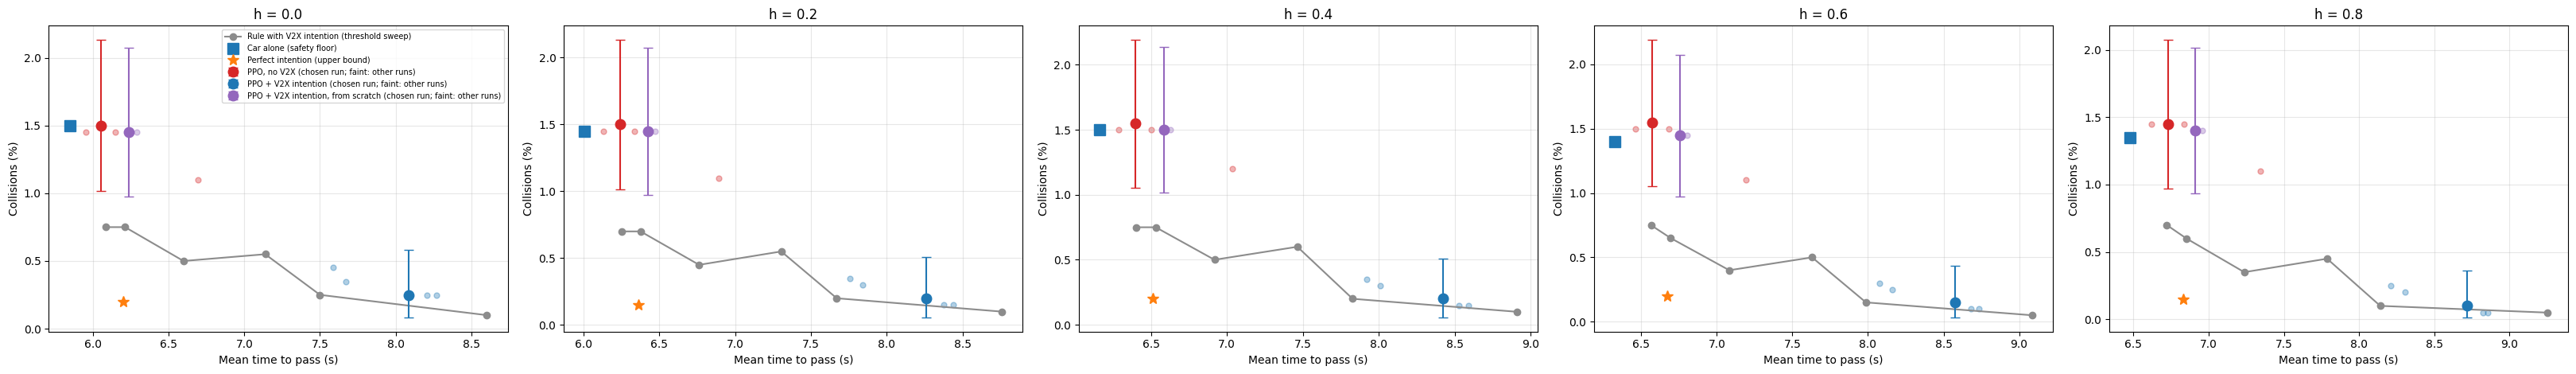

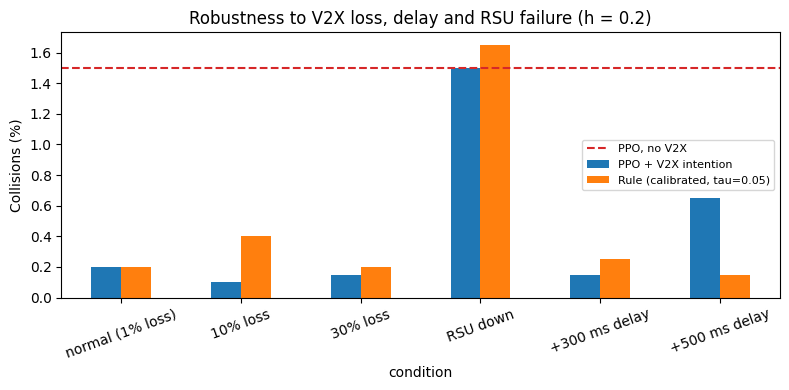

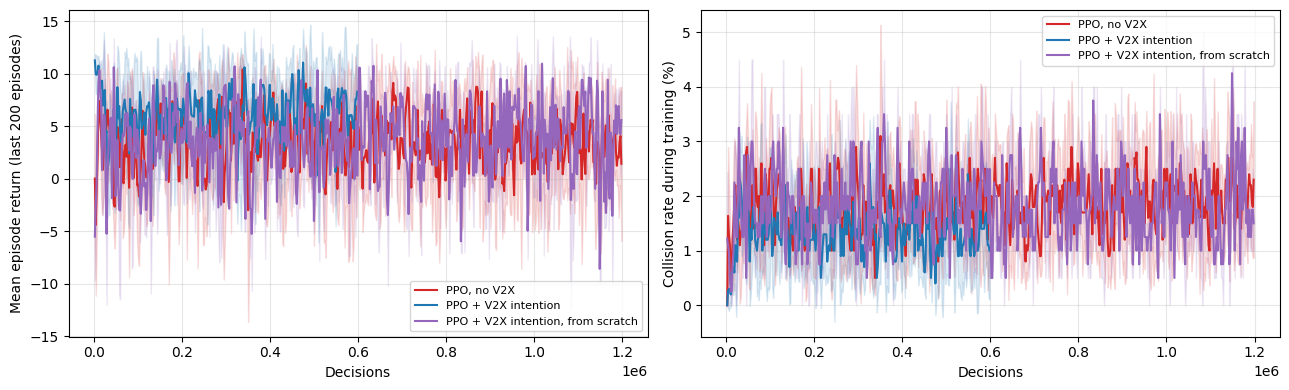

In [16]:
# ===== CELL E: plots
fig, axes = plt.subplots(1, len(EVAL_H), figsize=(6.5 * len(EVAL_H), 4.8), squeeze=False)
for ax, h in zip(axes[0], EVAL_H):
    s = summary[summary.h == h]
    r = s[s.group == "rule"].sort_values("time_to_pass_s")
    ax.plot(r.time_to_pass_s, r.collision_pct, "-o", color="0.55", label="Rule with V2X intention (threshold sweep)")
    for _, q in s[s.group.isin(["baseline", "bound"])].iterrows():
        ax.plot(q.time_to_pass_s, q.collision_pct, "s" if q.group == "baseline" else "*", ms=10, label=q.policy)
    for name, col in zip(VARIANTS, ("tab:red", "tab:blue", "tab:purple", "tab:green")):
        p = s[s.policy == name]
        ax.scatter(p.time_to_pass_s, p.collision_pct, color=col, alpha=0.35, s=25)
        c = p[p.run == chosen[name]].iloc[0]
        ax.errorbar(c.time_to_pass_s, c.collision_pct, yerr=[[c.collision_pct - c.ci_low], [c.ci_high - c.collision_pct]],
                    fmt="o", color=col, ms=9, capsize=4, label=f"{name} (chosen run; faint: other runs)")
    ax.set_xlabel("Mean time to pass (s)"); ax.set_ylabel("Collisions (%)"); ax.set_title(f"h = {h}"); ax.grid(alpha=0.3)
axes[0][0].legend(fontsize=7)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(8, 4))
piv = robust_df.pivot(index="condition", columns="policy", values="collision_pct").reindex([c for c, _ in ROBUST])
piv.plot.bar(ax=ax, rot=20)
ax.axhline(ref.collision_pct, color="tab:red", ls="--", label="PPO, no V2X")
ax.set_ylabel("Collisions (%)"); ax.set_title("Robustness to V2X loss, delay and RSU failure (h = 0.2)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name, col in zip(VARIANTS, ("tab:red", "tab:blue", "tab:purple", "tab:green")):
    logs = [torch.load(os.path.join(run_dir, f"{slug(name)}_run{r}.pt"), map_location="cpu", weights_only=False)["log"] for r in range(VARIANTS[name]["runs"])]
    n = min(len(l["frames"]) for l in logs)
    fr = np.array(logs[0]["frames"][:n])
    for ax, key, sc in ((axes[0], "ep_return", 1), (axes[1], "collision", 100)):
        y = np.array([np.array(l[key][:n]) * sc for l in logs])
        ax.plot(fr, y.mean(0), color=col, label=name); ax.fill_between(fr, y.mean(0) - y.std(0), y.mean(0) + y.std(0), color=col, alpha=0.15)
axes[0].set_ylabel("Mean episode return (last 200 episodes)"); axes[1].set_ylabel("Collision rate during training (%)")
for ax in axes: ax.set_xlabel("Decisions"); ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()


## Export of the training logs
Reads the saved checkpoints and writes `training_logs_v6.csv` (used for the training figures).

In [1]:
from google.colab import drive
drive.mount('/content/drive')
import os, torch, pandas as pd
d = "/content/drive/MyDrive/Colab Notebooks/checkpoints_v6/env4480df20_v6e447b6bc_ppo8cd5154a_t0.05"
rows = []
for f in sorted(os.listdir(d)):
    if not (f.startswith("PPO") and f.endswith(".pt")):
        continue
    ck = torch.load(os.path.join(d, f), map_location="cpu", weights_only=False)
    L, x = ck["log"], ck["extra"]
    for i in range(0, len(L["update"]), 3):
        rows.append(dict(file=f, kind="train", frames=L["frames"][i], ret=round(L["ep_return"][i], 3),
                         coll=round(L["collision"][i], 4), near=round(L["near_miss"][i], 4), time=round(L["ep_time"][i], 2)))
    for u, v in zip(L["val_update"], L["val_return"]):
        rows.append(dict(file=f, kind="val", frames=(u + 1) * 2048, ret=round(v, 3)))
    rows.append(dict(file=f, kind="chosen", ret=round(x["val"], 3), note=str(x.get("candidates"))))
pd.DataFrame(rows).to_csv(os.path.join(d, "training_logs_v6.csv"), index=False)
print(len(rows), "rows saved")

Mounted at /content/drive
2012 rows saved
